# Deep Learning
## Practical Deep Learning Tutorial with PyTorch - Tutorial N° 2

### 2025-2026

# Importing necessary libraries

In [1]:
import torch
import torch.nn as nn
from torch.autograd import grad
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import make_blobs, make_moons

# Adaline

1. Build the ADALINE model using the `nn.Module` class. The model performs a linear transformation $\hat{y} = Xw^T + b$, with weights and bias initialised to zero.

In [ ]:
class Adaline(torch.nn.Module):
    def __init__(self, num_features):
        super(Adaline, self).__init__()
        self.linear =  nn.Linear(num_features, 1) #CONSIGNE
        with torch.no_grad():
            self.linear.weight.zero_() #CONSIGNE
            self.linear.bias.zero_() #CONSIGNE
    def forward(self, x):
        activations = self.linear(x)
        return activations.view(-1)

2. Using 'iris.txt', create a binary dataset in 2-D : the last 100 instances of iris described only by the 2nd and 3rd features.

    Split the dataset into training and test sets (70%, 30%).

    Normalize the dataset. **Why must the mean and standard deviation be computed on the training set only?**

In [ ]:
df = pd.read_csv('iris.txt', index_col=None, header=None)
df.columns = ['x1', 'x2', 'x3', 'x4', 'y']
df = df.iloc[50:150]                         # last 100 instances (2 last classes)
df['y'] = df['y'].apply(lambda x: 0 if x == 'Iris-versicolor' else 1)

# Assign features and target
X = torch.tensor(df[['x2', 'x3']].values, dtype=torch.float)
y = torch.tensor(df['y'].values, dtype=torch.int)

# Shuffling & train/test split
torch.manual_seed(123)
shuffle_idx = torch.randperm(y.size(0), dtype=torch.long)
percent70 = int(shuffle_idx.size(0)*0.7)
X_train, X_test = X[shuffle_idx[:percent70]], X[shuffle_idx[percent70:]]
y_train, y_test = y[shuffle_idx[:percent70]], y[shuffle_idx[percent70:]]

# Normalize (mean zero, unit variance) : CONSIGNE 
mu, sigma = X.mean(), X.std()
X_train = (X_train - mu)/sigma
X_test = (X_test - mu)/sigma

mu_train, sigma_train = X_train.mean(), X_train.std()

print(f"Moyenne : {mu_train} & Sigma : {sigma_train}")


Moyenne : 0.020521756261587143 & Sigma : 0.9827577471733093


In [11]:
model = Adaline(num_features=X_train.size(1))
model

Adaline(
  (linear): Linear(in_features=2, out_features=1, bias=True)
)

3. Train the model : we will use `MSELoss` (mean squared error) as loss function. The optimizer is SGD (Stochastic Gradient Descent) with learning rate 0.01.

    The function `train` must **return the list of the loss values at each epoch**. Plot this cost curve.

In [ ]:
def train(model, x, y, num_epochs, learning_rate, seed):
    cost = []
    torch.manual_seed(seed)
    optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate) 
    loss = nn.MSELoss() 
    for e in range(num_epochs):
        y_pred = model(x)
        #y_pred = model.forward(x)
        
        loss_value = loss(y_pred,y)
        optimizer.zero_grad()

        loss_value.backward()

        optimizer.step()#IMPORTANT Sans ça on a une droite et non une courbe
        #Cette instruction permet de mettre à jour les paramètres du modèle après le calcul des gradients.

        cost.append(loss_value.item())
        #CONSIGNE : 
        # forward pass, loss, gradient reset, backward pass, update
        # store the loss of the epoch in cost
        pass
    return cost

[0.5285714268684387, 0.49141258001327515, 0.45784732699394226, 0.42752090096473694, 0.40011343359947205, 0.3753369450569153, 0.35293179750442505, 0.33266425132751465, 0.3143235743045807, 0.2977200150489807, 0.28268250823020935, 0.26905691623687744, 0.2567044794559479, 0.24550001323223114, 0.23533090949058533, 0.2260955572128296, 0.2177024632692337, 0.21006916463375092, 0.2031213492155075, 0.1967921108007431, 0.19102106988430023, 0.18575389683246613, 0.1809415966272354, 0.17654001712799072, 0.17250937223434448, 0.1688137948513031, 0.1654210090637207, 0.16230185329914093, 0.15943007171154022, 0.15678204596042633, 0.1543363779783249, 0.15207388997077942, 0.14997723698616028, 0.14803078770637512, 0.14622046053409576, 0.14453354477882385, 0.1429585963487625, 0.14148525893688202, 0.14010421931743622, 0.13880705833435059, 0.13758625090122223, 0.1364348828792572, 0.13534682989120483, 0.13431650400161743, 0.13333885371685028, 0.13240933418273926, 0.13152387738227844, 0.13067878782749176, 0.1298

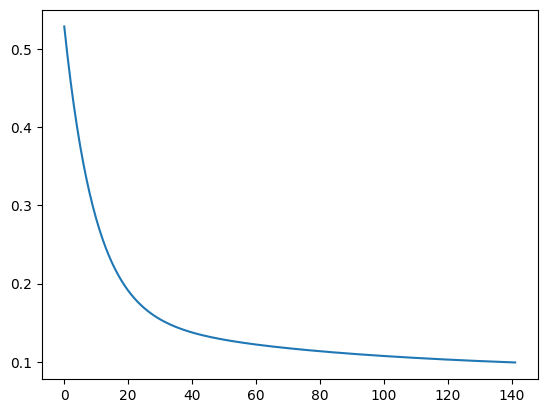

In [13]:
cost = train(model, X_train, y_train.float(), num_epochs=142, learning_rate=0.01, seed=123)
print(cost)
plt.plot(cost)
plt.show()

4. Compute the model accuracy

In [14]:
def custom_where(cond, x_1, x_2):
    return (cond * x_1) + (torch.logical_not(cond) * x_2)

train_pred = model.forward(X_train)
train_acc = torch.mean((custom_where(train_pred > 0.5, 1, 0).int() == y_train).float())
test_pred = model.forward(X_test)
test_acc = torch.mean((custom_where(test_pred > 0.5, 1, 0).int() == y_test).float())
print('Training Accuracy: %.2f' % (train_acc*100))
print('Test Accuracy: %.2f' % (test_acc*100))
print('Weights', model.linear.weight)
print('Bias', model.linear.bias)

Training Accuracy: 92.86
Test Accuracy: 96.67
Weights Parameter containing:
tensor([[-0.0557,  0.4622]], requires_grad=True)
Bias Parameter containing:
tensor([0.1102], requires_grad=True)


5. a. Plot the training points (one color per class) and the decision boundary of the Adaline. Give the equation of this boundary as a function of $w_1$, $w_2$ and $b$ (be careful: the threshold is 0.5, not 0).

   b. Train a new Adaline for each learning rate in {0.001, 0.01, 0.1, 0.5} and plot the 4 cost curves on the same figure. What happens for the largest value? Explain.

In [ ]:
#...

# Perceptron

6. Build a Perceptron model **from scratch** (without autograd and without optimizer):
    - `forward` returns the predictions in {0, 1} (step function),
    - `backward` returns the errors $y - \hat{y}$,
    - `train` applies the perceptron learning rule example by example, and must **return the number of misclassified examples at each epoch**.

In [ ]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

class Perceptron():
    def __init__(self, num_features):
        self.num_features = num_features
        self.weights = torch.zeros(num_features, 1, dtype=torch.float32, device=device)
        self.bias = torch.zeros(1, dtype=torch.float32, device=device)
        self.ones = torch.ones(1, device=device)
        self.zeros = torch.zeros(1, device=device)

    def forward(self, x): #CHATGPT
        y  = torch.mm(x, self.weights) + self.bias
        prediction = torch.where(y > 0, self.ones, self.zeros)
        return prediction

    def backward(self, x, y):
        y_ = self.forward(x)
        errors = y  - y_
        return errors

    def train(self, x, y, epochs):
        n_errors = []
        for e in range(epochs):
            for i in range(y.shape[0]):
                errors =   y[i] - self.forward(x[i])
                self.weights +=   errors * x[i]
                self.bias += errors
            # TODO : count the misclassified examples after this epoch
        return n_errors

    def evaluate(self, x, y):
        predictions = self.forward(x).reshape(-1)
        accuracy = torch.sum(predictions == y).float() / y.shape[0]
        return accuracy

7. Load the 'perceptron_toydata' dataset

    Split the dataset into train and test sets

    Normalize the data

In [ ]:
df = pd.read_csv('perceptron_toydata.txt', index_col=None, header=None, delimiter='\t')
df.columns = ['x1', 'x2', 'y']
X = torch.tensor(df[['x1', 'x2']].values, dtype=torch.float)
y = torch.tensor(df['y'].values, dtype=torch.int)
print('Class label counts:', torch.bincount(y))
print('X.shape:', X.shape)
print('y.shape:', y.shape)

# Shuffling & train/test split
torch.manual_seed(123)
shuffle_idx = torch.randperm(y.size(0), dtype=torch.long)
percent70 = int(shuffle_idx.size(0)*0.7)
X_train, X_test = X[shuffle_idx[:percent70]], X[shuffle_idx[percent70:]]
y_train, y_test = y[shuffle_idx[:percent70]], y[shuffle_idx[percent70:]]

# Normalize (mean zero, unit variance)
mu, sigma = X_train.mean(axis=0), X_train.std(axis=0)
X_train = (X_train - mu) / sigma
X_test = (X_test - mu) / sigma

8. Train the perceptron and plot the number of errors per epoch.

In [ ]:
model = Perceptron(num_features=2)

X_train_tensor = X_train.clone().detach().to(device)
y_train_tensor = y_train.clone().detach().float().to(device)

n_errors = model.train(X_train_tensor, y_train_tensor, epochs=5)

print('Model parameters:')
print('  Weights: %s' % model.weights)
print('  Bias: %s' % model.bias)
# TODO : plot n_errors

9. Evaluate the model (accuracy)

In [ ]:
X_test_tensor = X_test.clone().detach().to(device)
y_test_tensor = y_test.clone().detach().float().to(device)

test_acc = model.evaluate(X_test_tensor, y_test_tensor)
print('Test set accuracy: %.2f%%' % (test_acc*100))

10. a. Plot the test points and the decision boundary of the perceptron.

    b. Under which condition on the data is the perceptron learning rule guaranteed to converge? Train your perceptron for 20 epochs on the **iris dataset of the Adaline part** and plot the number of errors per epoch. What do you observe? Compare with the Adaline and explain.

# Multi Layer Perceptron

Unlike the single-layer perceptron, the Multi Layer Perceptron models have hidden layers
between the input and the output layers. After every hidden layer, an activation function
is applied to introduce non-linearity.

11. Build a simple Multi Layer Perceptron model with one hidden layer.
After the hidden layer, we will use ReLU as activation before the information is sent to the output layer.
As an output activation function, we will use Sigmoid.

In [ ]:
class MultilayerPerceptron(torch.nn.Module):
    def __init__(self, num_features, num_hidden_1):
        super(MultilayerPerceptron, self).__init__()
        # TODO

    def forward(self, x):
        # TODO
        return out

12. Create a random dataset and assign binary labels {0,1}

In [ ]:
def blob_label(y, label, loc): # assign labels
    target = np.copy(y)
    for l in loc:
        target[y == l] = label
    return target

x_train, y_train = make_blobs(n_samples=40, n_features=2, cluster_std=1.5, shuffle=True, random_state=0)
x_train = torch.FloatTensor(x_train)
y_train = torch.FloatTensor(blob_label(y_train, 0, [0]))
y_train = torch.FloatTensor(blob_label(y_train, 1, [1,2,3]))
x_test, y_test = make_blobs(n_samples=10, n_features=2, cluster_std=1.5, shuffle=True, random_state=1)
x_test = torch.FloatTensor(x_test)
y_test = torch.FloatTensor(blob_label(y_test, 0, [0]))
y_test = torch.FloatTensor(blob_label(y_test, 1, [1,2,3]))
print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)

13. Define the model with input dimension 2 and hidden dimension 10.
Since the task is to classify binary labels, we can use as criterion BCELoss (Binary Cross Entropy Loss).
The optimizer is SGD (Stochastic Gradient Descent) with learning rate 0.01.

In [ ]:
model = MultilayerPerceptron(2, 10)
criterion =      # TODO
optimizer =      # TODO

14. Check the test loss before the model training and compare it with the test loss after the training.

In [ ]:
model.eval()
y_pred = model(x_test)
before_train = criterion(y_pred.squeeze(), y_test)
print('Test loss before training' , before_train.item())

In [ ]:
model.train()
epoch = 20
for epoch in range(epoch):
    optimizer.zero_grad()
    y_pred =        # TODO
    loss =          # TODO
    print('Epoch {}: train loss: {}'.format(epoch, loss.item()))
    # Backward pass
    loss.backward()
    optimizer.step()

In [ ]:
model.eval()
y_pred = model(x_test)
after_train = criterion(y_pred.squeeze(), y_test)
print('Test loss after Training' , after_train.item())

15. Write a function `accuracy(model, x, y)`. Re-initialise the model and train it for 500 epochs, recording at each epoch the train loss, the test loss and the test accuracy. Plot the two loss curves on the same figure and comment (under-fitting / over-fitting?).

16. Non linearly separable data. Generate a dataset with `make_moons(n_samples=300, noise=0.2, random_state=0)` (train/test split 70/30).

    a. Train a single-layer model (`nn.Linear(2, 1)` followed by a Sigmoid, BCE loss) and your MLP.

    b. For each model, plot the decision regions (hint: evaluate the model on a grid built with `np.meshgrid`, then use `plt.contourf`) and give the test accuracy.

    c. Conclude: what does the hidden layer bring?

17. In order to improve the model, you can try out different values for your
hyperparameters (hidden dimension size, number of epochs, learning rate). You can also
try changing the structure of your model (adding more hidden layers). Summarize your experiments in a table (configuration, test accuracy) and justify your best choice.